In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
plant1_gen = pd.read_csv("../Dataset/Plant_1_Generation_Data.csv")
plant1_weather = pd.read_csv("../Dataset/Plant_1_Weather_Sensor_Data.csv")

plant2_gen = pd.read_csv("../Dataset/Plant_2_Generation_Data.csv")
plant2_weather = pd.read_csv("../Dataset/Plant_2_Weather_Sensor_Data.csv")

print("Plant 1 Generation:", plant1_gen.shape)
print("Plant 1 Weather:", plant1_weather.shape)
print("Plant 2 Generation:", plant2_gen.shape)
print("Plant 2 Weather:", plant2_weather.shape)

Plant 1 Generation: (68778, 7)
Plant 1 Weather: (3182, 6)
Plant 2 Generation: (67698, 7)
Plant 2 Weather: (3259, 6)


In [4]:
generation_df = pd.concat([plant1_gen, plant2_gen], ignore_index=True)
weather_df = pd.concat([plant1_weather, plant2_weather], ignore_index=True)

print("Combined generation shape:", generation_df.shape)
print("Combined weather shape:", weather_df.shape)

display(generation_df.head())
display(weather_df.head())

Combined generation shape: (136476, 7)
Combined weather shape: (6441, 6)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [5]:
print("Missing values in generation data:")
display(generation_df.isnull().sum())

print("Missing values in weather data:")
display(weather_df.isnull().sum())

print("Duplicate rows in generation data:", generation_df.duplicated().sum())
print("Duplicate rows in weather data:", weather_df.duplicated().sum())

Missing values in generation data:


DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Missing values in weather data:


DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Duplicate rows in generation data: 0
Duplicate rows in weather data: 0


In [6]:
# The source files contain more than one timestamp format, so use format='mixed'.
generation_df["DATE_TIME"] = pd.to_datetime(
    generation_df["DATE_TIME"], format="mixed", dayfirst=True
)
weather_df["DATE_TIME"] = pd.to_datetime(
    weather_df["DATE_TIME"], format="mixed", dayfirst=True
)

# Multiple inverter readings exist for each plant timestamp.
generation_agg = (
    generation_df
    .groupby(["DATE_TIME", "PLANT_ID"], as_index=False)["AC_POWER"]
    .sum()
)

print("Aggregated generation shape:", generation_agg.shape)
display(generation_agg.head())

Aggregated generation shape: (6417, 3)


,DATE_TIME,PLANT_ID,AC_POWER
0,2020-05-15 00:00:00,4135001,0.0
1,2020-05-15 00:00:00,4136001,0.0
2,2020-05-15 00:15:00,4135001,0.0
3,2020-05-15 00:15:00,4136001,0.0
4,2020-05-15 00:30:00,4135001,0.0


In [7]:
final_df = pd.merge(
    generation_agg,
    weather_df,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner"
)

final_df["PLANT"] = final_df["PLANT_ID"].map({
    4135001: "Plant 1",
    4136001: "Plant 2"
})

print("Final integrated dataset shape:", final_df.shape)
display(final_df.head())
print("Missing values after integration:")
display(final_df.isnull().sum())

Final integrated dataset shape: (6416, 8)


,DATE_TIME,PLANT_ID,AC_POWER,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT
0,2020-05-15 00:00:00,4135001,0.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,Plant 1
1,2020-05-15 00:00:00,4136001,0.0,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,Plant 2
2,2020-05-15 00:15:00,4135001,0.0,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,Plant 1
3,2020-05-15 00:15:00,4136001,0.0,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0,Plant 2
4,2020-05-15 00:30:00,4135001,0.0,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,Plant 1


Missing values after integration:


DATE_TIME              0
PLANT_ID               0
AC_POWER               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
PLANT                  0
dtype: int64

In [8]:
final_df.to_csv("../Results/solar_power_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [9]:
df = pd.read_csv("../Results/solar_power_cleaned.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe())

Dataset shape: (6416, 8)


,DATE_TIME,PLANT_ID,AC_POWER,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PLANT
0,2020-05-15 00:00:00,4135001,0.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,Plant 1
1,2020-05-15 00:00:00,4136001,0.0,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,Plant 2
2,2020-05-15 00:15:00,4135001,0.0,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0,Plant 1
3,2020-05-15 00:15:00,4136001,0.0,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0,Plant 2
4,2020-05-15 00:30:00,4135001,0.0,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0,Plant 1


,DATE_TIME,PLANT_ID,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,6416,6.416000e+03,6416.000000,6416.000000,6416.000000,6416.000000
mean,2020-06-01 03:19:58.784289536,4.135509e+06,5844.946416,26.834773,31.986625,0.231441
min,2020-05-15 00:00:00,4.135001e+06,0.000000,20.398505,18.140415,0.000000
25%,2020-05-23 17:30:00,4.135001e+06,0.000000,23.673180,22.466628,0.000000
50%,2020-06-01 06:15:00,4.136001e+06,638.473810,25.973933,26.478017,0.023582
75%,2020-06-09 15:03:45,4.136001e+06,11898.456667,29.366598,40.932470,0.445586
max,2020-06-17 23:45:00,4.136001e+06,29150.212499,39.181638,66.635953,1.221652
std,NaN,4.999758e+02,7576.958173,3.934008,11.836145,0.307142


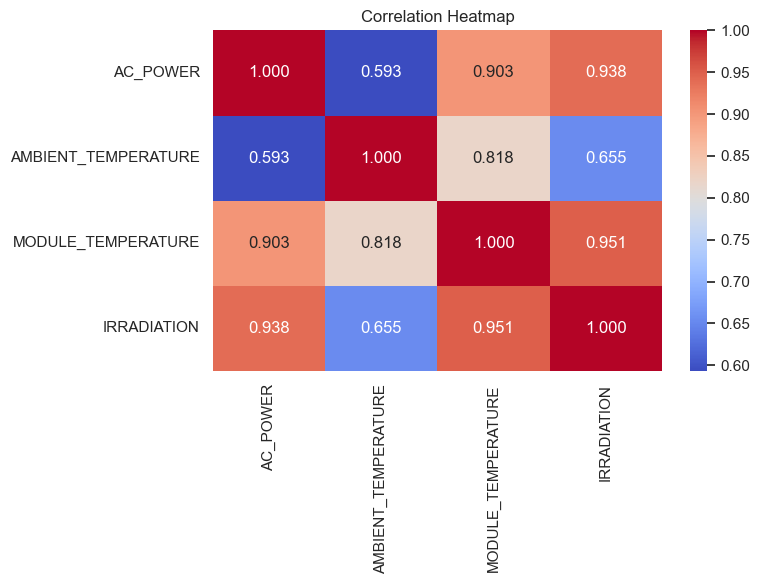

In [10]:
# Correlation heatmap for numerical variables
numeric_cols = [
    "AC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

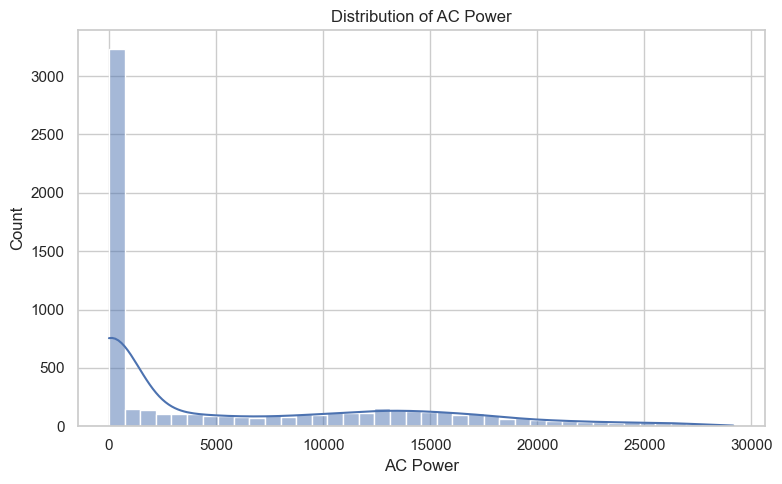

In [11]:
# Distribution of AC power
plt.figure(figsize=(8, 5))
sns.histplot(df["AC_POWER"], bins=40, kde=True)
plt.title("Distribution of AC Power")
plt.xlabel("AC Power")
plt.tight_layout()
plt.show()

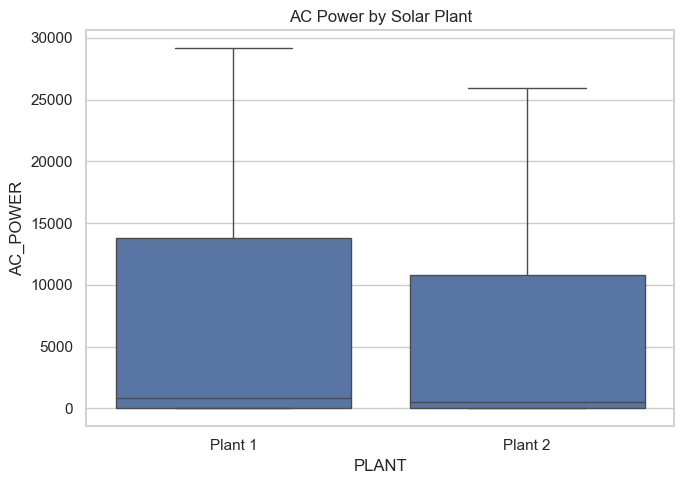

In [12]:
# AC power distribution by plant
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="PLANT", y="AC_POWER")
plt.title("AC Power by Solar Plant")
plt.tight_layout()
plt.show()

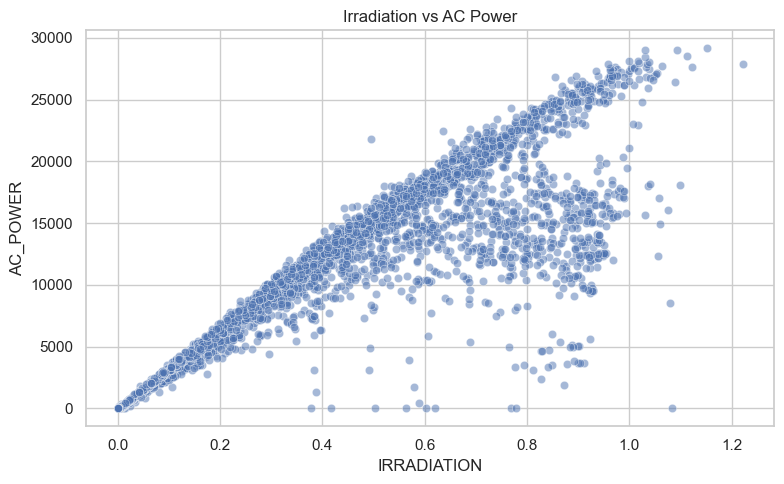

In [13]:
# Irradiation vs AC power
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="IRRADIATION", y="AC_POWER", alpha=0.5)
plt.title("Irradiation vs AC Power")
plt.tight_layout()
plt.show()

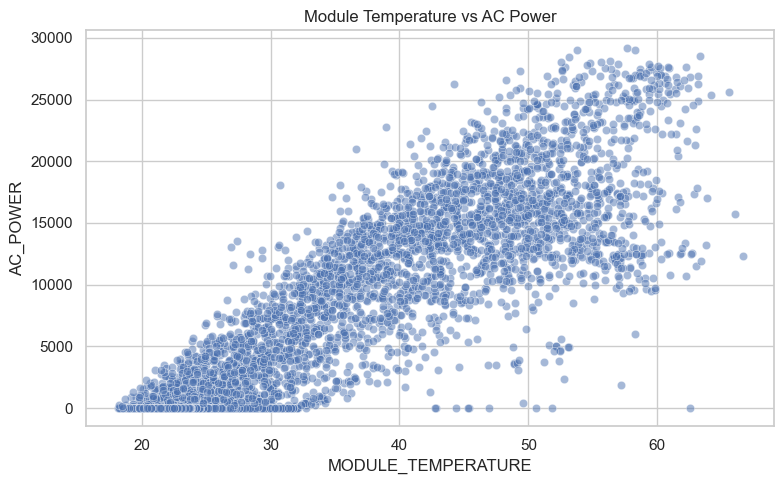

In [14]:
# Module temperature vs AC power
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MODULE_TEMPERATURE", y="AC_POWER", alpha=0.5)
plt.title("Module Temperature vs AC Power")
plt.tight_layout()
plt.show()

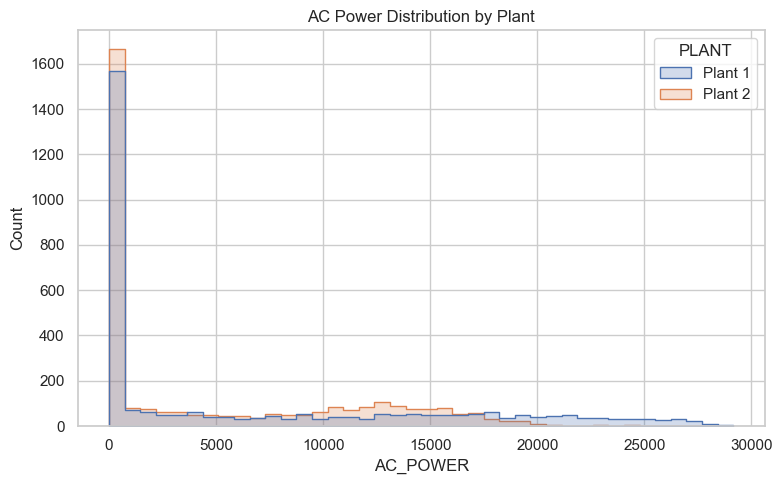

In [15]:
# AC power distribution for each plant
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="AC_POWER", hue="PLANT", bins=40, element="step")
plt.title("AC Power Distribution by Plant")
plt.tight_layout()
plt.show()

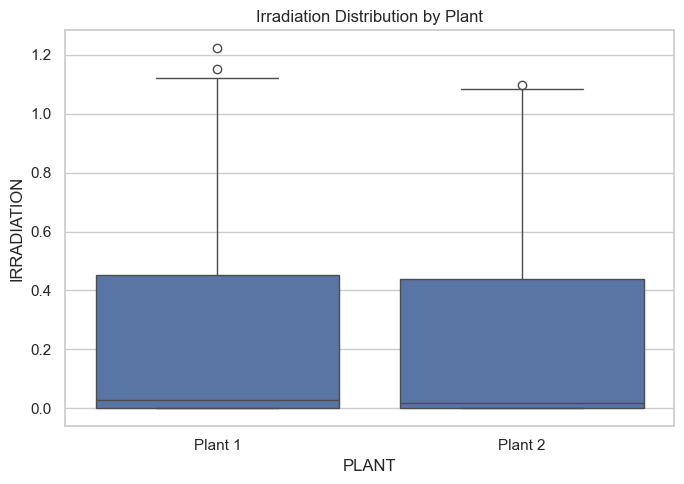

In [16]:
# Irradiation distribution by plant
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="PLANT", y="IRRADIATION")
plt.title("Irradiation Distribution by Plant")
plt.tight_layout()
plt.show()

In [17]:
correlations = df[numeric_cols].corr()["AC_POWER"].drop("AC_POWER")
display(correlations.sort_values(ascending=False))

IRRADIATION            0.938184
MODULE_TEMPERATURE     0.903046
AMBIENT_TEMPERATURE    0.593164
Name: AC_POWER, dtype: float64

In [18]:
X = df[[
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]]
y = df["AC_POWER"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5132, 3)
X_test: (1284, 3)
y_train: (5132,)
y_test: (1284,)


In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
X_single = df[["IRRADIATION"]]
y_single = df["AC_POWER"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_single, y_single, test_size=0.2, random_state=42
)

simple_lr = LinearRegression()
simple_lr.fit(X_train_s, y_train_s)

simple_pred = simple_lr.predict(X_test_s)

simple_r2 = r2_score(y_test_s, simple_pred)
simple_mae = mean_absolute_error(y_test_s, simple_pred)
simple_rmse = np.sqrt(mean_squared_error(y_test_s, simple_pred))

print("Simple Linear Regression")
print("Slope:", simple_lr.coef_[0])
print("Intercept:", simple_lr.intercept_)
print(f"Equation: AC_POWER = {simple_lr.intercept_:.3f} + {simple_lr.coef_[0]:.3f} × IRRADIATION")
print("R2 Score:", simple_r2)
print("MAE:", simple_mae)
print("RMSE:", simple_rmse)

Simple Linear Regression
Slope: 23105.44622453328
Intercept: 492.20398621931054
Equation: AC_POWER = 492.204 + 23105.446 × IRRADIATION
R2 Score: 0.8881779556140152
MAE: 1541.3686427211312
RMSE: 2581.3206897999557


In [23]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred = lr_model.predict(X_test_scaled)

multiple_r2 = r2_score(y_test, y_pred)
multiple_mae = mean_absolute_error(y_test, y_pred)
multiple_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Multiple Linear Regression")
print("R2 Score:", multiple_r2)
print("MAE:", multiple_mae)
print("RMSE:", multiple_rmse)

Multiple Linear Regression
R2 Score: 0.9030936905142692
MAE: 1438.5848963845722
RMSE: 2403.002793298807


In [24]:
model_comparison = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "R2 Score": [simple_r2, multiple_r2],
    "MAE": [simple_mae, multiple_mae],
    "RMSE": [simple_rmse, multiple_rmse]
})

display(model_comparison)
model_comparison.to_csv("../Results/model_comparison.csv", index=False)
print("Model comparison saved successfully!")

,Model,R2 Score,MAE,RMSE
0,Simple Linear Regression,0.888178,1541.368643,2581.320690
1,Multiple Linear Regression,0.903094,1438.584896,2403.002793


Model comparison saved successfully!


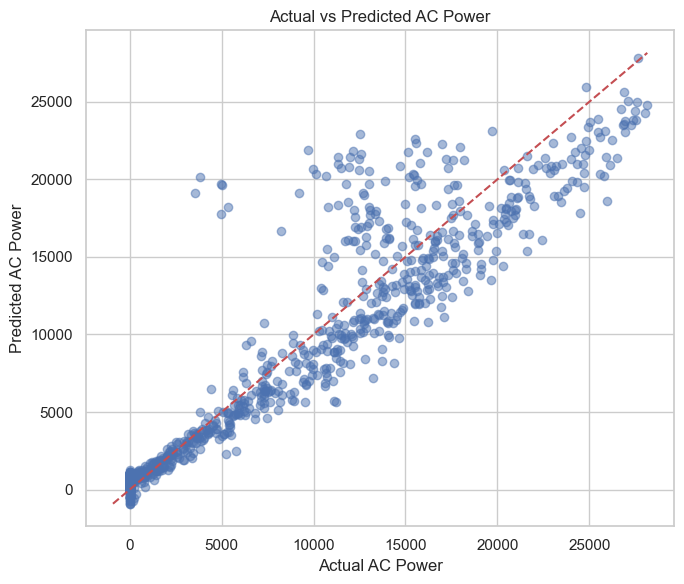

In [25]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual AC Power")
plt.ylabel("Predicted AC Power")
plt.title("Actual vs Predicted AC Power")
plt.tight_layout()
plt.show()

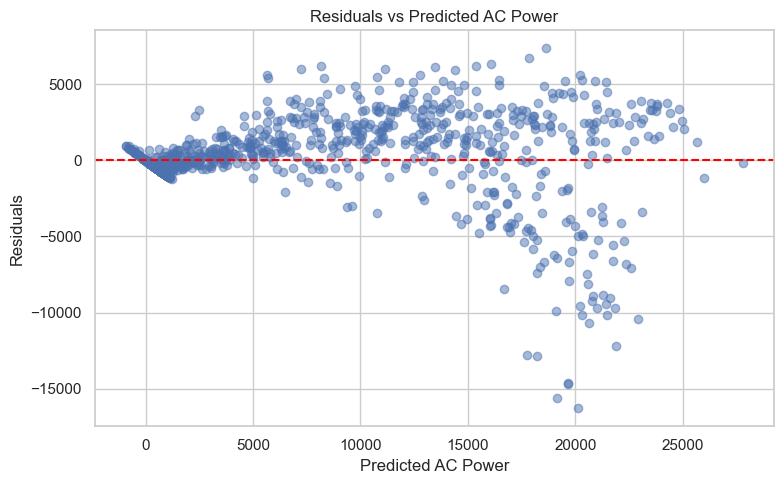

In [26]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted AC Power")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted AC Power")
plt.tight_layout()
plt.show()

In [28]:
comparison_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Plant": df.loc[y_test.index, "PLANT"]
})

plant_results = []

for plant in comparison_df["Plant"].unique():
    plant_data = comparison_df[comparison_df["Plant"] == plant]

    plant_results.append({
        "Plant": plant,
        "R2 Score": r2_score(plant_data["Actual"], plant_data["Predicted"]),
        "MAE": mean_absolute_error(plant_data["Actual"], plant_data["Predicted"]),
        "RMSE": np.sqrt(mean_squared_error(plant_data["Actual"], plant_data["Predicted"]))
    })

plant_comparison = pd.DataFrame(plant_results)
display(plant_comparison)

plant_comparison.to_csv("../Results/plant_wise_comparison.csv", index=False)
print("Plant-wise comparison saved successfully!")

,Plant,R2 Score,MAE,RMSE
0,Plant 2,0.787708,1721.542742,2945.062808
1,Plant 1,0.963023,1152.970169,1687.669846


Plant-wise comparison saved successfully!


In [29]:
plant_correlations = df.groupby("PLANT").apply(
    lambda group: group["IRRADIATION"].corr(group["AC_POWER"]),
    include_groups=False
)
display(plant_correlations)

PLANT
Plant 1    0.995864
Plant 2    0.911084
dtype: float64

In [30]:
joblib.dump(lr_model, "../Results/solar_model.pkl")
joblib.dump(scaler, "../Results/solar_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [31]:
print("Simple Linear Regression R2:", round(simple_r2, 6))
print("Multiple Linear Regression R2:", round(multiple_r2, 6))
print("Best model: Multiple Linear Regression" if multiple_r2 > simple_r2 else "Best model: Simple Linear Regression")
print("Final integrated dataset shape:", df.shape)

Simple Linear Regression R2: 0.888178
Multiple Linear Regression R2: 0.903094
Best model: Multiple Linear Regression
Final integrated dataset shape: (6416, 8)
